# Attribution Score Over Time, by Outlet Political Lean

This notebook builds a companion chart to Figure 1 of the paper
("Attribution Index Over Time"), splitting article-level attribution
scores by the political lean of the outlet that published them:
**Left-leaning**, **Right-leaning**, and **Unidentified** (no
individually-rated domain).

It reuses the `Domain`, `Ad Fontes Bias Score`, and `Political Lean
Group` columns that were added directly to the `Master` sheet of
`attribution.xlsx`. See Section 5.5 ("Variation by Outlet
Characteristics") of the paper for the full methodology behind the
Ad Fontes Bias score itself.

**Unit of analysis:** unlike Figure 1 (which averages to one point per
*disaster*), this chart averages to one point per *article*
($a_{i,d}$), since outlet lean is only defined at the article level —
the same disaster is often covered by both a left- and a right-leaning
outlet, so collapsing to a disaster-level number would throw away the
variation we actually care about here.

## 1. Load the data

We read the `Master` sheet directly rather than re-deriving the
lean lookup, since the lookup (domain extraction from each article's
URL, joined to the `Domain Ratings` sheet's Ad Fontes Bias score) is
already persisted as columns on `Master`.

In [1]:
import openpyxl
from collections import defaultdict
import statistics as stats
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

ATTRIBUTION_XLSX = "../attribution.xlsx"

wb = openpyxl.load_workbook(ATTRIBUTION_XLSX, read_only=True, data_only=True)
ws = wb["Master"]
rows = list(ws.iter_rows(values_only=True))
header = rows[0]
idx = {h: i for i, h in enumerate(header)}

print(f"Master sheet: {len(rows) - 1} rows, {len(header)} columns")
print("Lean-related columns:",
      [h for h in header if h in ("Domain", "Ad Fontes Bias Score",
                                   "AllSides Rating (Numeric)", "Political Lean Group")])

Master sheet: 1694 rows, 30 columns
Lean-related columns: ['Domain', 'Ad Fontes Bias Score', 'AllSides Rating (Numeric)', 'Political Lean Group']


## 2. Grouping logic

Every **Relevant** article is assigned to one of three groups based on
its `Political Lean Group` value (already computed on `Master` from
the sign of the Ad Fontes Bias score):

- **Left-leaning** — negative Ad Fontes Bias score
- **Right-leaning** — positive Ad Fontes Bias score
- **Unidentified** — domain has no individually-rated Ad Fontes Bias
  score (either because the domain was never individually rated, or
  because it was rated but had no numeric score available — e.g.
  al.com, whose Ad Fontes page had a data error)

We bucket every Relevant article's attribution score ($a_{i,d} \in
\{-1, 0, 0.5, 1\}$) into its group, by the calendar year of the
disaster's begin date.

In [2]:
by_year = defaultdict(lambda: defaultdict(list))
right_all = []  # (year, score) pairs for Right-leaning, kept separately for binning

for r in rows[1:]:
    if r[idx["Relevance"]] != "Relevant":
        continue
    begin = r[idx["Begin Date"]]
    if begin is None:
        continue
    year = int(str(begin)[:4])
    score = r[idx["Attribution Score"]]
    if score is None:
        continue
    grp = r[idx["Political Lean Group"]]
    by_year[year][grp].append(float(score))
    if grp == "Right-leaning":
        right_all.append((year, float(score)))

total_relevant = sum(len(v) for yr in by_year.values() for v in yr.values())
print(f"Total Relevant, scored articles: {total_relevant}")

Total Relevant, scored articles: 1252


## 3. Summary counts by group

Before building the chart, it's worth seeing exactly how thin the
Right-leaning group is relative to the other two — this is what drives
the binning decision below.

In [3]:
group_totals = defaultdict(int)
for yr in by_year.values():
    for grp, vals in yr.items():
        group_totals[grp] += len(vals)

print(f"{'Group':<16} {'Articles':>9} {'Share':>8}")
for grp in ["Left-leaning", "Right-leaning", "Unidentified"]:
    n = group_totals.get(grp, 0)
    print(f"{grp:<16} {n:>9} {100*n/total_relevant:>7.1f}%")

Group             Articles    Share
Left-leaning           869    69.4%
Right-leaning           20     1.6%
Unidentified           363    29.0%


## 4. Mean / standard error helper

A small helper to compute the mean, standard error, and count for a
list of article-level scores. Standard error is undefined (set to 0)
for a single-article group.

In [4]:
def mean_se(vals):
    n = len(vals)
    if n == 0:
        return None, None, 0
    m = sum(vals) / n
    se = stats.stdev(vals) / (n ** 0.5) if n > 1 else 0.0
    return m, se, n

## 5. Annual series for Left-leaning and Unidentified

Both groups have enough articles per year (mostly n \u2265 3, often
n > 20 in recent years) to support an annual mean, matching how
Figure 1 aggregates by year.

In [5]:
years = sorted(by_year)

def series(group):
    ys, ms, ses, ns = [], [], [], []
    for y in years:
        m, se, n = mean_se(by_year[y].get(group, []))
        if n:
            ys.append(y); ms.append(m); ses.append(se); ns.append(n)
    return ys, ms, ses, ns

left_y, left_m, left_se, left_n = series("Left-leaning")
unid_y, unid_m, unid_se, unid_n = series("Unidentified")

print(f"Left-leaning: {len(left_y)} years with data, article counts range {min(left_n)}-{max(left_n)}")
print(f"Unidentified: {len(unid_y)} years with data, article counts range {min(unid_n)}-{max(unid_n)}")

Left-leaning: 24 years with data, article counts range 3-111
Unidentified: 21 years with data, article counts range 1-49


## 6. Binned periods for Right-leaning

The Right-leaning group has only 20 articles across the entire
2000\u20132024 sample (see Section 3 above), spread thinly across a
handful of years \u2014 several years have zero Right-leaning
articles at all. An annual mean would mostly be undefined or based on
1\u20132 articles, which isn't a meaningful average.

Instead we bin Right-leaning articles into three periods chosen to
roughly balance the number of articles per bin, given the real gaps in
the data:

- **2000\u20132019** \u2014 the sparse early period (a handful of
  articles scattered across two decades)
- **2020\u20132021** \u2014 where Right-leaning coverage picks up
  most sharply
- **2022\u20132024** \u2014 the most recent period

This is a deliberate simplification for visualization purposes only;
it should not be read as implying anything structural changed exactly
at 2020 or 2022 \u2014 those breakpoints were chosen to keep bin
sizes usable (n=5, n=9, n=6), not because of a hypothesized mechanism.

In [6]:
right_bins = [(2000, 2019), (2020, 2021), (2022, 2024)]

for lo, hi in right_bins:
    vals = [s for y, s in right_all if lo <= y <= hi]
    m, se, n = mean_se(vals)
    print(f"{lo}-{hi}: n={n}, mean={m}")

2000-2019: n=5, mean=0.0
2020-2021: n=9, mean=0.3333333333333333
2022-2024: n=6, mean=0.16666666666666666


## 7. Build the chart

Left-leaning (blue circles) and Unidentified (gray squares) are
plotted as annual means with \u00b11 SE error bars, each point
labeled with its article count. Right-leaning (red diamonds) is
plotted as three binned means, each spanning its period as a
horizontal segment, also labeled with its article count.

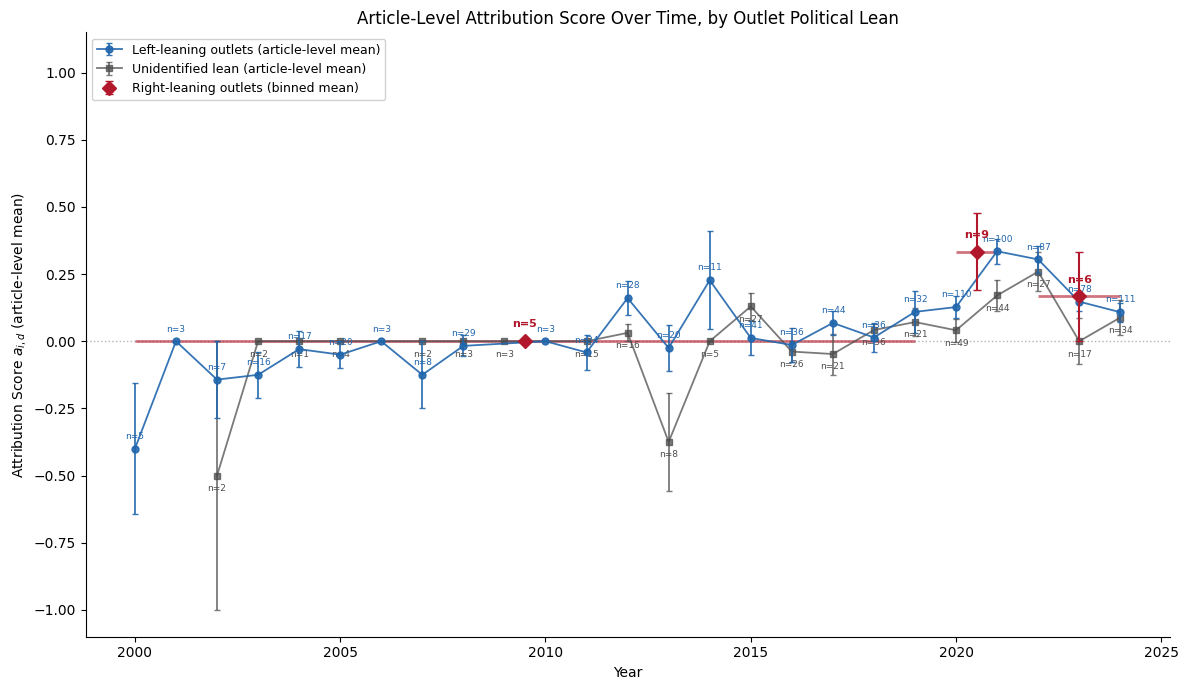

In [7]:
fig, ax = plt.subplots(figsize=(12, 7))

ax.axhline(0, color="0.7", linestyle=":", linewidth=1, zorder=0)

# --- Left-leaning: annual means ---
ax.errorbar(left_y, left_m, yerr=left_se, fmt="o-", color="#2166ac",
            label="Left-leaning outlets (article-level mean)",
            markersize=5, linewidth=1.3, capsize=2, alpha=0.9, zorder=3)
for x, y, n in zip(left_y, left_m, left_n):
    ax.annotate(f"n={n}", (x, y), textcoords="offset points", xytext=(0, 7),
                ha="center", fontsize=6.5, color="#2166ac")

# --- Unidentified: annual means ---
ax.errorbar(unid_y, unid_m, yerr=unid_se, fmt="s-", color="#4d4d4d",
            label="Unidentified lean (article-level mean)",
            markersize=5, linewidth=1.3, capsize=2, alpha=0.75, zorder=2)
for x, y, n in zip(unid_y, unid_m, unid_n):
    ax.annotate(f"n={n}", (x, y), textcoords="offset points", xytext=(0, -11),
                ha="center", fontsize=6.5, color="#4d4d4d")

# --- Right-leaning: binned means ---
for i, (lo, hi) in enumerate(right_bins):
    vals = [s for y, s in right_all if lo <= y <= hi]
    m, se, n = mean_se(vals)
    if n == 0:
        continue
    mid = (lo + hi) / 2
    ax.errorbar([mid], [m], yerr=[se], fmt="D", color="#b2182b",
                markersize=7, capsize=3, zorder=4,
                label="Right-leaning outlets (binned mean)" if i == 0 else None)
    ax.hlines(m, lo, hi, color="#b2182b", linewidth=2, alpha=0.6, zorder=1)
    ax.annotate(f"n={n}", (mid, m), textcoords="offset points",
                xytext=(0, 10), ha="center", fontsize=8, color="#b2182b",
                fontweight="bold")

ax.set_xlabel("Year")
ax.set_ylabel(r"Attribution Score $a_{i,d}$ (article-level mean)")
ax.set_title("Article-Level Attribution Score Over Time, by Outlet Political Lean")
ax.set_ylim(-1.1, 1.15)
ax.xaxis.set_major_locator(mticker.MultipleLocator(5))
ax.legend(loc="upper left", fontsize=9, framealpha=0.9)
ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
fig.savefig("../paper/outlet_lean_memo/figures/attribution_by_lean.pdf")
fig.savefig("../paper/outlet_lean_memo/figures/attribution_by_lean.png", dpi=200)
plt.show()

## 8. Caveats

- The Right-leaning line rests on only 20 articles total across 25
  years \u2014 even binned, the widest bin (2020\u20132021) has just
  n=9. Treat it as illustrative, not statistically reliable.
- \"Unidentified\" is not a political-lean category in itself \u2014
  it's simply every article from a domain with no individually-rated
  Ad Fontes Bias score. It shouldn't be read as \"centrist\" coverage.
- These are raw group means with no controls (no disaster-type or
  year adjustment), unlike the regression in Table `outlet_results` in
  the paper. This chart is a descriptive companion to that regression,
  not a replacement for it.